In [1]:
import logging
import warnings

import itertools
import numpy

logging.basicConfig(level=logging.ERROR)
warnings.filterwarnings("ignore", category=SyntaxWarning)

In [2]:
from IPython.core.display import Markdown
from IPython.display import display

from library.qubit_array import QubitArray
from library.surface_code.patch import SurfaceCodePatch
from library.circuitry import Circuitry
from library.compact_magic_state_cultivation import MagicStateCultivation
from library.utils.clifft.stratified_mc_reweighted import compute_ler_curves
from library.utils.clifft.plotting import plot_logical_error_rates, plot_conditional_error_rates

In [3]:
TARGET_DISTANCE = 7

if TARGET_DISTANCE % 2 != 1 and TARGET_DISTANCE < 7:
    raise ValueError("TARGET_DISTANCE must be odd and above 7.")

TELEPORT_ROUNDS = 3
minimum_anchoring = 1 + int(TARGET_DISTANCE == 7)
TARGET_ANCHOR = (minimum_anchoring, minimum_anchoring)

scenarios = {}

In [4]:
qubits: QubitArray = SurfaceCodePatch.make_array(TARGET_DISTANCE, (2, 2))
circuitry = Circuitry(qubits)
magic = SurfaceCodePatch(
    qubits, distance=TARGET_DISTANCE, anchor=(minimum_anchoring, minimum_anchoring)
)
msc = MagicStateCultivation(qubits, target=magic)

msc.append_injection(circuitry)

msc.annotate_detectors(circuitry, sdc_rounds=0, tpt_rounds=0, exp_rounds=0)

msc.steane.append_noiseless_measurement(circuitry)
circuitry.attach_observable(0, "STN:NOISELESS:CC")

scenarios["Injected"] = circuitry

In [5]:
qubits = SurfaceCodePatch.make_array(TARGET_DISTANCE, (2, 2))
circuitry = Circuitry(qubits)
magic = SurfaceCodePatch(
    qubits, distance=TARGET_DISTANCE, anchor=(minimum_anchoring, minimum_anchoring)
)
msc = MagicStateCultivation(qubits, target=magic)

msc.append_injection(circuitry)
msc.append_superdense_cycle(circuitry, prefix="STN:SDC0")

msc.annotate_detectors(circuitry, sdc_rounds=1, tpt_rounds=0, exp_rounds=0)

msc.steane.annotate_stabilizers(circuitry, style="DIFFUSE", noiseless=True)
for stabilizer, color in itertools.product("XZ", "RGB"):
    circuitry.annotate_detector(f"STN:{stabilizer}{color}", postselected=True)

msc.steane.append_noiseless_measurement(circuitry, compact=False)
circuitry.attach_observable(0, "STN:NOISELESS:CC")

scenarios["Superdense"] = circuitry

In [6]:
qubits = SurfaceCodePatch.make_array(TARGET_DISTANCE, (2, 2))
circuitry = Circuitry(qubits)
magic = SurfaceCodePatch(
    qubits, distance=TARGET_DISTANCE, anchor=(minimum_anchoring, minimum_anchoring)
)
msc = MagicStateCultivation(qubits, target=magic)

msc.append_injection(circuitry)
msc.append_superdense_cycle(circuitry, prefix="STN:SDC0")
msc.append_doublecheck(circuitry)

msc.annotate_detectors(circuitry, sdc_rounds=1, tpt_rounds=0, exp_rounds=0)

msc.steane.annotate_stabilizers(circuitry, style="DIFFUSE", noiseless=True)
for stabilizer, color in itertools.product("XZ", "RGB"):
    circuitry.annotate_detector(f"STN:{stabilizer}{color}", postselected=True)

msc.steane.append_noiseless_measurement(circuitry, compact=False)
circuitry.attach_observable(0, "STN:NOISELESS:CC")

scenarios["Double-check"] = circuitry

In [7]:
for index, (scenario, circuitry) in enumerate(scenarios.items()):
    label = f"Point {index} - {scenario}"
    display(Markdown(f"[Open in Crumble ({label})]({circuitry.to_crumble_url()})"))

[Open in Crumble (Point 0 - Injected)](https://algassert.com/crumble.html#circuit=QUBIT_COORDS(2,_2)_0;QUBIT_COORDS(2,_3)_1;QUBIT_COORDS(2,_4)_2;QUBIT_COORDS(2,_5)_3;QUBIT_COORDS(2,_6)_4;QUBIT_COORDS(2,_7)_5;QUBIT_COORDS(2,_8)_6;QUBIT_COORDS(3,_2)_7;QUBIT_COORDS(3,_3)_8;QUBIT_COORDS(3,_4)_9;QUBIT_COORDS(3,_5)_10;QUBIT_COORDS(3,_6)_11;QUBIT_COORDS(3,_7)_12;QUBIT_COORDS(3,_8)_13;QUBIT_COORDS(4,_1)_14;QUBIT_COORDS(4,_2)_15;QUBIT_COORDS(4,_3)_16;QUBIT_COORDS(4,_4)_17;QUBIT_COORDS(4,_5)_18;QUBIT_COORDS(4,_6)_19;QUBIT_COORDS(4,_7)_20;QUBIT_COORDS(4,_8)_21;QUBIT_COORDS(5,_1)_22;QUBIT_COORDS(5,_2)_23;QUBIT_COORDS(5,_3)_24;QUBIT_COORDS(5,_4)_25;QUBIT_COORDS(5,_5)_26;QUBIT_COORDS(5,_6)_27;QUBIT_COORDS(5,_7)_28;QUBIT_COORDS(5,_8)_29;QUBIT_COORDS(6,_2)_30;QUBIT_COORDS(6,_3)_31;QUBIT_COORDS(6,_4)_32;QUBIT_COORDS(6,_5)_33;QUBIT_COORDS(6,_6)_34;QUBIT_COORDS(6,_7)_35;QUBIT_COORDS(6,_8)_36;QUBIT_COORDS(7,_2)_37;QUBIT_COORDS(7,_3)_38;QUBIT_COORDS(7,_4)_39;QUBIT_COORDS(7,_5)_40;QUBIT_COORDS(7,_6)_41;QUBIT_COORDS(7,_7)_42;QUBIT_COORDS(7,_8)_43;QUBIT_COORDS(8,_2)_44;QUBIT_COORDS(8,_3)_45;QUBIT_COORDS(8,_4)_46;QUBIT_COORDS(8,_5)_47;QUBIT_COORDS(8,_6)_48;QUBIT_COORDS(8,_7)_49;QUBIT_COORDS(8,_8)_50;QUBIT_COORDS(3.5,_2.5)_51;QUBIT_COORDS(4.5,_1.5)_52;QUBIT_COORDS(4.5,_2.5)_53;QUBIT_COORDS(5.5,_1.5)_54;QUBIT_COORDS(5.5,_2.5)_55;POLYGON(1,0,0,0.125)_7_0;POLYGON(1,0,0,0.125)_1_8_9_2;POLYGON(1,0,0,0.125)_3_10_11_4;POLYGON(1,0,0,0.125)_5_12_13_6;POLYGON(1,0,0,0.125)_7_15_16_8;POLYGON(1,0,0,0.125)_9_17_18_10;POLYGON(1,0,0,0.125)_11_19_20_12;POLYGON(1,0,0,0.125)_13_21;POLYGON(1,0,0,0.125)_23_15;POLYGON(1,0,0,0.125)_16_24_25_17;POLYGON(1,0,0,0.125)_18_26_27_19;POLYGON(1,0,0,0.125)_20_28_29_21;POLYGON(1,0,0,0.125)_23_30_31_24;POLYGON(1,0,0,0.125)_25_32_33_26;POLYGON(1,0,0,0.125)_27_34_35_28;POLYGON(1,0,0,0.125)_29_36;POLYGON(1,0,0,0.125)_37_30;POLYGON(1,0,0,0.125)_31_38_39_32;POLYGON(1,0,0,0.125)_33_40_41_34;POLYGON(1,0,0,0.125)_35_42_43_36;POLYGON(1,0,0,0.125)_37_44_45_38;POLYGON(1,0,0,0.125)_39_46_47_40;POLYGON(1,0,0,0.125)_41_48_49_42;POLYGON(1,0,0,0.125)_43_50;POLYGON(0,0,1,0.125)_1_2;POLYGON(0,0,1,0.125)_3_4;POLYGON(0,0,1,0.125)_5_6;POLYGON(0,0,1,0.125)_0_7_8_1;POLYGON(0,0,1,0.125)_2_9_10_3;POLYGON(0,0,1,0.125)_4_11_12_5;POLYGON(0,0,1,0.125)_8_16_17_9;POLYGON(0,0,1,0.125)_10_18_19_11;POLYGON(0,0,1,0.125)_12_20_21_13;POLYGON(0,0,1,0.125)_15_23_24_16;POLYGON(0,0,1,0.125)_17_25_26_18;POLYGON(0,0,1,0.125)_19_27_28_20;POLYGON(0,0,1,0.125)_24_31_32_25;POLYGON(0,0,1,0.125)_26_33_34_27;POLYGON(0,0,1,0.125)_28_35_36_29;POLYGON(0,0,1,0.125)_30_37_38_31;POLYGON(0,0,1,0.125)_32_39_40_33;POLYGON(0,0,1,0.125)_34_41_42_35;POLYGON(0,0,1,0.125)_38_45_46_39;POLYGON(0,0,1,0.125)_40_47_48_41;POLYGON(0,0,1,0.125)_42_49_50_43;POLYGON(0,0,1,0.125)_44_45;POLYGON(0,0,1,0.125)_46_47;POLYGON(0,0,1,0.125)_48_49;POLYGON(1,0,0,0.5)_24_23_54_55;POLYGON(0,1,0,0.5)_23_15_22_54;POLYGON(0,0,1,0.5)_24_53_15_23;RX_24_23_54_15;R_51_31_14_30_55_22_52_16_53;TICK;CX_24_53_23_55_54_22;TICK;CX_24_55_23_53_54_30_22_52;TICK;CX_15_53_30_55_52_22;TICK;CX_54_30_15_52_55_31_53_16;TICK;CX_23_52_31_55_16_51;TICK;CX_51_15_16_53;TICK;CX_51_16_52_15;TICK;S_15;CX_52_14;TICK;CX_52_15;TICK;CX_51_15_14_52;TICK;S_24_54_15;S_DAG_51_23_31_14;RX_55_52;TICK;CX_52_14_15_51_23_54_55_31;TICK;CX_52_15_55_24;TICK;CX_23_55;TICK;CX_52_23;TICK;MX_52;TICK;OBSERVABLE_INCLUDE(0)_rec[-1])

[Open in Crumble (Point 1 - Superdense)](https://algassert.com/crumble.html#circuit=QUBIT_COORDS(2,_2)_0;QUBIT_COORDS(2,_3)_1;QUBIT_COORDS(2,_4)_2;QUBIT_COORDS(2,_5)_3;QUBIT_COORDS(2,_6)_4;QUBIT_COORDS(2,_7)_5;QUBIT_COORDS(2,_8)_6;QUBIT_COORDS(3,_2)_7;QUBIT_COORDS(3,_3)_8;QUBIT_COORDS(3,_4)_9;QUBIT_COORDS(3,_5)_10;QUBIT_COORDS(3,_6)_11;QUBIT_COORDS(3,_7)_12;QUBIT_COORDS(3,_8)_13;QUBIT_COORDS(4,_1)_14;QUBIT_COORDS(4,_2)_15;QUBIT_COORDS(4,_3)_16;QUBIT_COORDS(4,_4)_17;QUBIT_COORDS(4,_5)_18;QUBIT_COORDS(4,_6)_19;QUBIT_COORDS(4,_7)_20;QUBIT_COORDS(4,_8)_21;QUBIT_COORDS(5,_1)_22;QUBIT_COORDS(5,_2)_23;QUBIT_COORDS(5,_3)_24;QUBIT_COORDS(5,_4)_25;QUBIT_COORDS(5,_5)_26;QUBIT_COORDS(5,_6)_27;QUBIT_COORDS(5,_7)_28;QUBIT_COORDS(5,_8)_29;QUBIT_COORDS(6,_1)_30;QUBIT_COORDS(6,_2)_31;QUBIT_COORDS(6,_3)_32;QUBIT_COORDS(6,_4)_33;QUBIT_COORDS(6,_5)_34;QUBIT_COORDS(6,_6)_35;QUBIT_COORDS(6,_7)_36;QUBIT_COORDS(6,_8)_37;QUBIT_COORDS(7,_2)_38;QUBIT_COORDS(7,_3)_39;QUBIT_COORDS(7,_4)_40;QUBIT_COORDS(7,_5)_41;QUBIT_COORDS(7,_6)_42;QUBIT_COORDS(7,_7)_43;QUBIT_COORDS(7,_8)_44;QUBIT_COORDS(8,_2)_45;QUBIT_COORDS(8,_3)_46;QUBIT_COORDS(8,_4)_47;QUBIT_COORDS(8,_5)_48;QUBIT_COORDS(8,_6)_49;QUBIT_COORDS(8,_7)_50;QUBIT_COORDS(8,_8)_51;QUBIT_COORDS(3.5,_2.5)_52;QUBIT_COORDS(4.5,_0.5)_53;QUBIT_COORDS(4.5,_1.5)_54;QUBIT_COORDS(4.5,_2.5)_55;QUBIT_COORDS(4.5,_3.5)_56;QUBIT_COORDS(5.5,_1.5)_57;QUBIT_COORDS(5.5,_2.5)_58;QUBIT_COORDS(6.5,_2.5)_59;POLYGON(1,0,0,0.125)_7_0;POLYGON(1,0,0,0.125)_1_8_9_2;POLYGON(1,0,0,0.125)_3_10_11_4;POLYGON(1,0,0,0.125)_5_12_13_6;POLYGON(1,0,0,0.125)_7_15_16_8;POLYGON(1,0,0,0.125)_9_17_18_10;POLYGON(1,0,0,0.125)_11_19_20_12;POLYGON(1,0,0,0.125)_13_21;POLYGON(1,0,0,0.125)_23_15;POLYGON(1,0,0,0.125)_16_24_25_17;POLYGON(1,0,0,0.125)_18_26_27_19;POLYGON(1,0,0,0.125)_20_28_29_21;POLYGON(1,0,0,0.125)_23_31_32_24;POLYGON(1,0,0,0.125)_25_33_34_26;POLYGON(1,0,0,0.125)_27_35_36_28;POLYGON(1,0,0,0.125)_29_37;POLYGON(1,0,0,0.125)_38_31;POLYGON(1,0,0,0.125)_32_39_40_33;POLYGON(1,0,0,0.125)_34_41_42_35;POLYGON(1,0,0,0.125)_36_43_44_37;POLYGON(1,0,0,0.125)_38_45_46_39;POLYGON(1,0,0,0.125)_40_47_48_41;POLYGON(1,0,0,0.125)_42_49_50_43;POLYGON(1,0,0,0.125)_44_51;POLYGON(0,0,1,0.125)_1_2;POLYGON(0,0,1,0.125)_3_4;POLYGON(0,0,1,0.125)_5_6;POLYGON(0,0,1,0.125)_0_7_8_1;POLYGON(0,0,1,0.125)_2_9_10_3;POLYGON(0,0,1,0.125)_4_11_12_5;POLYGON(0,0,1,0.125)_8_16_17_9;POLYGON(0,0,1,0.125)_10_18_19_11;POLYGON(0,0,1,0.125)_12_20_21_13;POLYGON(0,0,1,0.125)_15_23_24_16;POLYGON(0,0,1,0.125)_17_25_26_18;POLYGON(0,0,1,0.125)_19_27_28_20;POLYGON(0,0,1,0.125)_24_32_33_25;POLYGON(0,0,1,0.125)_26_34_35_27;POLYGON(0,0,1,0.125)_28_36_37_29;POLYGON(0,0,1,0.125)_31_38_39_32;POLYGON(0,0,1,0.125)_33_40_41_34;POLYGON(0,0,1,0.125)_35_42_43_36;POLYGON(0,0,1,0.125)_39_46_47_40;POLYGON(0,0,1,0.125)_41_48_49_42;POLYGON(0,0,1,0.125)_43_50_51_44;POLYGON(0,0,1,0.125)_45_46;POLYGON(0,0,1,0.125)_47_48;POLYGON(0,0,1,0.125)_49_50;POLYGON(1,0,0,0.5)_24_23_57_58;POLYGON(0,1,0,0.5)_23_15_22_57;POLYGON(0,0,1,0.5)_24_55_15_23;RX_24_23_57_15;R_52_32_14_31_58_22_54_16_55;TICK;CX_24_55_23_58_57_22;TICK;CX_24_58_23_55_57_31_22_54;TICK;CX_15_55_31_58_54_22;TICK;CX_57_31_15_54_58_32_55_16;TICK;CX_23_54_32_58_16_52;TICK;CX_52_15_16_55;TICK;CX_52_16_54_15;TICK;S_15;CX_54_14;TICK;CX_54_15;TICK;CX_52_15_14_54;TICK;POLYGON(1,0,0,0.125)_7_0;POLYGON(1,0,0,0.125)_1_8_9_2;POLYGON(1,0,0,0.125)_3_10_11_4;POLYGON(1,0,0,0.125)_5_12_13_6;POLYGON(1,0,0,0.125)_7_15_16_8;POLYGON(1,0,0,0.125)_9_17_18_10;POLYGON(1,0,0,0.125)_11_19_20_12;POLYGON(1,0,0,0.125)_13_21;POLYGON(1,0,0,0.125)_23_15;POLYGON(1,0,0,0.125)_16_24_25_17;POLYGON(1,0,0,0.125)_18_26_27_19;POLYGON(1,0,0,0.125)_20_28_29_21;POLYGON(1,0,0,0.125)_23_31_32_24;POLYGON(1,0,0,0.125)_25_33_34_26;POLYGON(1,0,0,0.125)_27_35_36_28;POLYGON(1,0,0,0.125)_29_37;POLYGON(1,0,0,0.125)_38_31;POLYGON(1,0,0,0.125)_32_39_40_33;POLYGON(1,0,0,0.125)_34_41_42_35;POLYGON(1,0,0,0.125)_36_43_44_37;POLYGON(1,0,0,0.125)_38_45_46_39;POLYGON(1,0,0,0.125)_40_47_48_41;POLYGON(1,0,0,0.125)_42_49_50_43;POLYGON(1,0,0,0.125)_44_51;POLYGON(0,0,1,0.125)_1_2;POLYGON(0,0,1,0.125)_3_4;POLYGON(0,0,1,0.125)_5_6;POLYGON(0,0,1,0.125)_0_7_8_1;POLYGON(0,0,1,0.125)_2_9_10_3;POLYGON(0,0,1,0.125)_4_11_12_5;POLYGON(0,0,1,0.125)_8_16_17_9;POLYGON(0,0,1,0.125)_10_18_19_11;POLYGON(0,0,1,0.125)_12_20_21_13;POLYGON(0,0,1,0.125)_15_23_24_16;POLYGON(0,0,1,0.125)_17_25_26_18;POLYGON(0,0,1,0.125)_19_27_28_20;POLYGON(0,0,1,0.125)_24_32_33_25;POLYGON(0,0,1,0.125)_26_34_35_27;POLYGON(0,0,1,0.125)_28_36_37_29;POLYGON(0,0,1,0.125)_31_38_39_32;POLYGON(0,0,1,0.125)_33_40_41_34;POLYGON(0,0,1,0.125)_35_42_43_36;POLYGON(0,0,1,0.125)_39_46_47_40;POLYGON(0,0,1,0.125)_41_48_49_42;POLYGON(0,0,1,0.125)_43_50_51_44;POLYGON(0,0,1,0.125)_45_46;POLYGON(0,0,1,0.125)_47_48;POLYGON(0,0,1,0.125)_49_50;POLYGON(1,0,0,0.5)_24_23_57_32;POLYGON(0,1,0,0.5)_23_15_14_57;POLYGON(0,0,1,0.5)_24_52_15_23;RX_31_22_16;R_58_54_55_59_53_56_8_30;TICK;CX_31_58_22_54_16_55;TICK;CX_55_24_54_23_58_32;TICK;CX_58_24_55_23_31_57_54_15;TICK;CX_16_52_58_23_22_57_54_14_55_15;TICK;XCZ_16_52_58_23_22_57_54_14_55_15;TICK;XCZ_55_24_54_23_58_32_31_57;TICK;CX_24_58_23_55_15_54_31_59_22_53_16_56;TICK;CX_52_8_57_30_31_58_22_54_16_55;TICK;CX_8_52_30_57_59_31_53_22_56_16;TICK;MX_59_53_56;M_58_54_55;TICK;DETECTOR_rec[-6];DETECTOR_rec[-3];DETECTOR_rec[-5];DETECTOR_rec[-2];DETECTOR_rec[-4];DETECTOR_rec[-1];MPP_X23*X24*X30*X32;TICK;MPP_X14*X15*X23*X30;TICK;MPP_X8*X15*X23*X24;TICK;MPP_Z23*Z24*Z30*Z32;TICK;MPP_Z14*Z15*Z23*Z30;TICK;MPP_Z8*Z15*Z23*Z24;TICK;DETECTOR_rec[-6];DETECTOR_rec[-5];DETECTOR_rec[-4];DETECTOR_rec[-3];DETECTOR_rec[-2];DETECTOR_rec[-1];S_24_30_15;S_DAG_8_23_32_14;RX_58_54_52_57;TICK;CX_52_8_58_32_57_30_54_14;TICK;CX_15_52_23_57_58_24;TICK;CX_54_15_23_58;TICK;CX_54_23;TICK;MX_54;TICK;OBSERVABLE_INCLUDE(0)_rec[-1])

[Open in Crumble (Point 2 - Double-check)](https://algassert.com/crumble.html#circuit=QUBIT_COORDS(2,_2)_0;QUBIT_COORDS(2,_3)_1;QUBIT_COORDS(2,_4)_2;QUBIT_COORDS(2,_5)_3;QUBIT_COORDS(2,_6)_4;QUBIT_COORDS(2,_7)_5;QUBIT_COORDS(2,_8)_6;QUBIT_COORDS(3,_2)_7;QUBIT_COORDS(3,_3)_8;QUBIT_COORDS(3,_4)_9;QUBIT_COORDS(3,_5)_10;QUBIT_COORDS(3,_6)_11;QUBIT_COORDS(3,_7)_12;QUBIT_COORDS(3,_8)_13;QUBIT_COORDS(4,_1)_14;QUBIT_COORDS(4,_2)_15;QUBIT_COORDS(4,_3)_16;QUBIT_COORDS(4,_4)_17;QUBIT_COORDS(4,_5)_18;QUBIT_COORDS(4,_6)_19;QUBIT_COORDS(4,_7)_20;QUBIT_COORDS(4,_8)_21;QUBIT_COORDS(5,_1)_22;QUBIT_COORDS(5,_2)_23;QUBIT_COORDS(5,_3)_24;QUBIT_COORDS(5,_4)_25;QUBIT_COORDS(5,_5)_26;QUBIT_COORDS(5,_6)_27;QUBIT_COORDS(5,_7)_28;QUBIT_COORDS(5,_8)_29;QUBIT_COORDS(6,_1)_30;QUBIT_COORDS(6,_2)_31;QUBIT_COORDS(6,_3)_32;QUBIT_COORDS(6,_4)_33;QUBIT_COORDS(6,_5)_34;QUBIT_COORDS(6,_6)_35;QUBIT_COORDS(6,_7)_36;QUBIT_COORDS(6,_8)_37;QUBIT_COORDS(7,_2)_38;QUBIT_COORDS(7,_3)_39;QUBIT_COORDS(7,_4)_40;QUBIT_COORDS(7,_5)_41;QUBIT_COORDS(7,_6)_42;QUBIT_COORDS(7,_7)_43;QUBIT_COORDS(7,_8)_44;QUBIT_COORDS(8,_2)_45;QUBIT_COORDS(8,_3)_46;QUBIT_COORDS(8,_4)_47;QUBIT_COORDS(8,_5)_48;QUBIT_COORDS(8,_6)_49;QUBIT_COORDS(8,_7)_50;QUBIT_COORDS(8,_8)_51;QUBIT_COORDS(3.5,_1.5)_52;QUBIT_COORDS(3.5,_2.5)_53;QUBIT_COORDS(3.5,_3.5)_54;QUBIT_COORDS(4.5,_0.5)_55;QUBIT_COORDS(4.5,_1.5)_56;QUBIT_COORDS(4.5,_2.5)_57;QUBIT_COORDS(4.5,_3.5)_58;QUBIT_COORDS(5.5,_1.5)_59;QUBIT_COORDS(5.5,_2.5)_60;QUBIT_COORDS(6.5,_2.5)_61;POLYGON(1,0,0,0.125)_7_0;POLYGON(1,0,0,0.125)_1_8_9_2;POLYGON(1,0,0,0.125)_3_10_11_4;POLYGON(1,0,0,0.125)_5_12_13_6;POLYGON(1,0,0,0.125)_7_15_16_8;POLYGON(1,0,0,0.125)_9_17_18_10;POLYGON(1,0,0,0.125)_11_19_20_12;POLYGON(1,0,0,0.125)_13_21;POLYGON(1,0,0,0.125)_23_15;POLYGON(1,0,0,0.125)_16_24_25_17;POLYGON(1,0,0,0.125)_18_26_27_19;POLYGON(1,0,0,0.125)_20_28_29_21;POLYGON(1,0,0,0.125)_23_31_32_24;POLYGON(1,0,0,0.125)_25_33_34_26;POLYGON(1,0,0,0.125)_27_35_36_28;POLYGON(1,0,0,0.125)_29_37;POLYGON(1,0,0,0.125)_38_31;POLYGON(1,0,0,0.125)_32_39_40_33;POLYGON(1,0,0,0.125)_34_41_42_35;POLYGON(1,0,0,0.125)_36_43_44_37;POLYGON(1,0,0,0.125)_38_45_46_39;POLYGON(1,0,0,0.125)_40_47_48_41;POLYGON(1,0,0,0.125)_42_49_50_43;POLYGON(1,0,0,0.125)_44_51;POLYGON(0,0,1,0.125)_1_2;POLYGON(0,0,1,0.125)_3_4;POLYGON(0,0,1,0.125)_5_6;POLYGON(0,0,1,0.125)_0_7_8_1;POLYGON(0,0,1,0.125)_2_9_10_3;POLYGON(0,0,1,0.125)_4_11_12_5;POLYGON(0,0,1,0.125)_8_16_17_9;POLYGON(0,0,1,0.125)_10_18_19_11;POLYGON(0,0,1,0.125)_12_20_21_13;POLYGON(0,0,1,0.125)_15_23_24_16;POLYGON(0,0,1,0.125)_17_25_26_18;POLYGON(0,0,1,0.125)_19_27_28_20;POLYGON(0,0,1,0.125)_24_32_33_25;POLYGON(0,0,1,0.125)_26_34_35_27;POLYGON(0,0,1,0.125)_28_36_37_29;POLYGON(0,0,1,0.125)_31_38_39_32;POLYGON(0,0,1,0.125)_33_40_41_34;POLYGON(0,0,1,0.125)_35_42_43_36;POLYGON(0,0,1,0.125)_39_46_47_40;POLYGON(0,0,1,0.125)_41_48_49_42;POLYGON(0,0,1,0.125)_43_50_51_44;POLYGON(0,0,1,0.125)_45_46;POLYGON(0,0,1,0.125)_47_48;POLYGON(0,0,1,0.125)_49_50;POLYGON(1,0,0,0.5)_24_23_59_60;POLYGON(0,1,0,0.5)_23_15_22_59;POLYGON(0,0,1,0.5)_24_57_15_23;RX_24_23_59_15;R_53_32_14_31_60_22_56_16_57;TICK;CX_24_57_23_60_59_22;TICK;CX_24_60_23_57_59_31_22_56;TICK;CX_15_57_31_60_56_22;TICK;CX_59_31_15_56_60_32_57_16;TICK;CX_23_56_32_60_16_53;TICK;CX_53_15_16_57;TICK;CX_53_16_56_15;TICK;S_15;CX_56_14;TICK;CX_56_15;TICK;CX_53_15_14_56;TICK;POLYGON(1,0,0,0.125)_7_0;POLYGON(1,0,0,0.125)_1_8_9_2;POLYGON(1,0,0,0.125)_3_10_11_4;POLYGON(1,0,0,0.125)_5_12_13_6;POLYGON(1,0,0,0.125)_7_15_16_8;POLYGON(1,0,0,0.125)_9_17_18_10;POLYGON(1,0,0,0.125)_11_19_20_12;POLYGON(1,0,0,0.125)_13_21;POLYGON(1,0,0,0.125)_23_15;POLYGON(1,0,0,0.125)_16_24_25_17;POLYGON(1,0,0,0.125)_18_26_27_19;POLYGON(1,0,0,0.125)_20_28_29_21;POLYGON(1,0,0,0.125)_23_31_32_24;POLYGON(1,0,0,0.125)_25_33_34_26;POLYGON(1,0,0,0.125)_27_35_36_28;POLYGON(1,0,0,0.125)_29_37;POLYGON(1,0,0,0.125)_38_31;POLYGON(1,0,0,0.125)_32_39_40_33;POLYGON(1,0,0,0.125)_34_41_42_35;POLYGON(1,0,0,0.125)_36_43_44_37;POLYGON(1,0,0,0.125)_38_45_46_39;POLYGON(1,0,0,0.125)_40_47_48_41;POLYGON(1,0,0,0.125)_42_49_50_43;POLYGON(1,0,0,0.125)_44_51;POLYGON(0,0,1,0.125)_1_2;POLYGON(0,0,1,0.125)_3_4;POLYGON(0,0,1,0.125)_5_6;POLYGON(0,0,1,0.125)_0_7_8_1;POLYGON(0,0,1,0.125)_2_9_10_3;POLYGON(0,0,1,0.125)_4_11_12_5;POLYGON(0,0,1,0.125)_8_16_17_9;POLYGON(0,0,1,0.125)_10_18_19_11;POLYGON(0,0,1,0.125)_12_20_21_13;POLYGON(0,0,1,0.125)_15_23_24_16;POLYGON(0,0,1,0.125)_17_25_26_18;POLYGON(0,0,1,0.125)_19_27_28_20;POLYGON(0,0,1,0.125)_24_32_33_25;POLYGON(0,0,1,0.125)_26_34_35_27;POLYGON(0,0,1,0.125)_28_36_37_29;POLYGON(0,0,1,0.125)_31_38_39_32;POLYGON(0,0,1,0.125)_33_40_41_34;POLYGON(0,0,1,0.125)_35_42_43_36;POLYGON(0,0,1,0.125)_39_46_47_40;POLYGON(0,0,1,0.125)_41_48_49_42;POLYGON(0,0,1,0.125)_43_50_51_44;POLYGON(0,0,1,0.125)_45_46;POLYGON(0,0,1,0.125)_47_48;POLYGON(0,0,1,0.125)_49_50;POLYGON(1,0,0,0.5)_24_23_59_32;POLYGON(0,1,0,0.5)_23_15_14_59;POLYGON(0,0,1,0.5)_24_53_15_23;RX_31_22_16;R_60_56_57_61_55_58_8_30;TICK;CX_31_60_22_56_16_57;TICK;CX_57_24_56_23_60_32;TICK;CX_60_24_57_23_31_59_56_15;TICK;CX_16_53_60_23_22_59_56_14_57_15;TICK;XCZ_16_53_60_23_22_59_56_14_57_15;TICK;XCZ_57_24_56_23_60_32_31_59;TICK;CX_24_60_23_57_15_56_31_61_22_55_16_58;TICK;CX_53_8_59_30_31_60_22_56_16_57;TICK;CX_8_53_30_59_61_31_55_22_58_16;TICK;MX_61_55_58;M_60_56_57;TICK;POLYGON(1,0,0,0.125)_7_0;POLYGON(1,0,0,0.125)_1_8_9_2;POLYGON(1,0,0,0.125)_3_10_11_4;POLYGON(1,0,0,0.125)_5_12_13_6;POLYGON(1,0,0,0.125)_7_15_16_8;POLYGON(1,0,0,0.125)_9_17_18_10;POLYGON(1,0,0,0.125)_11_19_20_12;POLYGON(1,0,0,0.125)_13_21;POLYGON(1,0,0,0.125)_23_15;POLYGON(1,0,0,0.125)_16_24_25_17;POLYGON(1,0,0,0.125)_18_26_27_19;POLYGON(1,0,0,0.125)_20_28_29_21;POLYGON(1,0,0,0.125)_23_31_32_24;POLYGON(1,0,0,0.125)_25_33_34_26;POLYGON(1,0,0,0.125)_27_35_36_28;POLYGON(1,0,0,0.125)_29_37;POLYGON(1,0,0,0.125)_38_31;POLYGON(1,0,0,0.125)_32_39_40_33;POLYGON(1,0,0,0.125)_34_41_42_35;POLYGON(1,0,0,0.125)_36_43_44_37;POLYGON(1,0,0,0.125)_38_45_46_39;POLYGON(1,0,0,0.125)_40_47_48_41;POLYGON(1,0,0,0.125)_42_49_50_43;POLYGON(1,0,0,0.125)_44_51;POLYGON(0,0,1,0.125)_1_2;POLYGON(0,0,1,0.125)_3_4;POLYGON(0,0,1,0.125)_5_6;POLYGON(0,0,1,0.125)_0_7_8_1;POLYGON(0,0,1,0.125)_2_9_10_3;POLYGON(0,0,1,0.125)_4_11_12_5;POLYGON(0,0,1,0.125)_8_16_17_9;POLYGON(0,0,1,0.125)_10_18_19_11;POLYGON(0,0,1,0.125)_12_20_21_13;POLYGON(0,0,1,0.125)_15_23_24_16;POLYGON(0,0,1,0.125)_17_25_26_18;POLYGON(0,0,1,0.125)_19_27_28_20;POLYGON(0,0,1,0.125)_24_32_33_25;POLYGON(0,0,1,0.125)_26_34_35_27;POLYGON(0,0,1,0.125)_28_36_37_29;POLYGON(0,0,1,0.125)_31_38_39_32;POLYGON(0,0,1,0.125)_33_40_41_34;POLYGON(0,0,1,0.125)_35_42_43_36;POLYGON(0,0,1,0.125)_39_46_47_40;POLYGON(0,0,1,0.125)_41_48_49_42;POLYGON(0,0,1,0.125)_43_50_51_44;POLYGON(0,0,1,0.125)_45_46;POLYGON(0,0,1,0.125)_47_48;POLYGON(0,0,1,0.125)_49_50;POLYGON(1,0,0,0.5)_24_23_30_32;POLYGON(0,1,0,0.5)_23_15_14_30;POLYGON(0,0,1,0.5)_24_8_15_23;S_24_30_15;S_DAG_8_23_32_14;RX_31_16_60_56_53_57_59_52_54;R_61_58;TICK;CX_53_8_57_23_60_32_59_30_56_14_52_15_31_61_16_58;TICK;CX_24_58_60_31;TICK;CX_53_16_59_31;TICK;CX_15_53_23_59_60_24;TICK;CX_56_15_23_60;TICK;CX_56_23;TICK;MX_56;TICK;RX_56;TICK;CX_56_23;TICK;CX_56_15_23_60;TICK;CX_15_53_23_59_60_24;TICK;CX_53_16_59_31;TICK;CX_16_58_60_31;TICK;CX_53_8_57_23_60_32_59_30_56_14_52_15_54_16_24_58_31_61;TICK;MX_60_56_53_57_59_52_54;M_61_58;S_DAG_24_30_15;S_8_23_32_14;TICK;DETECTOR_rec[-16];DETECTOR_rec[-13];DETECTOR_rec[-15];DETECTOR_rec[-12];DETECTOR_rec[-14];DETECTOR_rec[-11];DETECTOR_rec[-10];DETECTOR_rec[-9];DETECTOR_rec[-8];DETECTOR_rec[-7];DETECTOR_rec[-6];DETECTOR_rec[-4];DETECTOR_rec[-3];DETECTOR_rec[-5];DETECTOR_rec[-2];DETECTOR_rec[-1];MPP_X23*X24*X30*X32;TICK;MPP_X14*X15*X23*X30;TICK;MPP_X8*X15*X23*X24;TICK;MPP_Z23*Z24*Z30*Z32;TICK;MPP_Z14*Z15*Z23*Z30;TICK;MPP_Z8*Z15*Z23*Z24;TICK;DETECTOR_rec[-6];DETECTOR_rec[-5];DETECTOR_rec[-4];DETECTOR_rec[-3];DETECTOR_rec[-2];DETECTOR_rec[-1];S_24_30_15;S_DAG_8_23_32_14;RX_60_56_53_59;TICK;CX_53_8_60_32_59_30_56_14;TICK;CX_15_53_23_59_60_24;TICK;CX_56_15_23_60;TICK;CX_56_23;TICK;MX_56;TICK;OBSERVABLE_INCLUDE(0)_rec[-1])

In [8]:
strata_count = 16
noise_levels = numpy.logspace(-7, -2, num=11)
ler_curves, cer_distributions = compute_ler_curves(
    scenarios,
    noise_levels = noise_levels,
    strata_count=strata_count,
    shots_per_stratum=1e6,
    postselection=True,
)

Computing Conditional Error Rates for Injected ...
> 0.54s
Computing Conditional Error Rates for Superdense ...
> 1.37s
Computing Conditional Error Rates for Double-check ...
> 1.84s


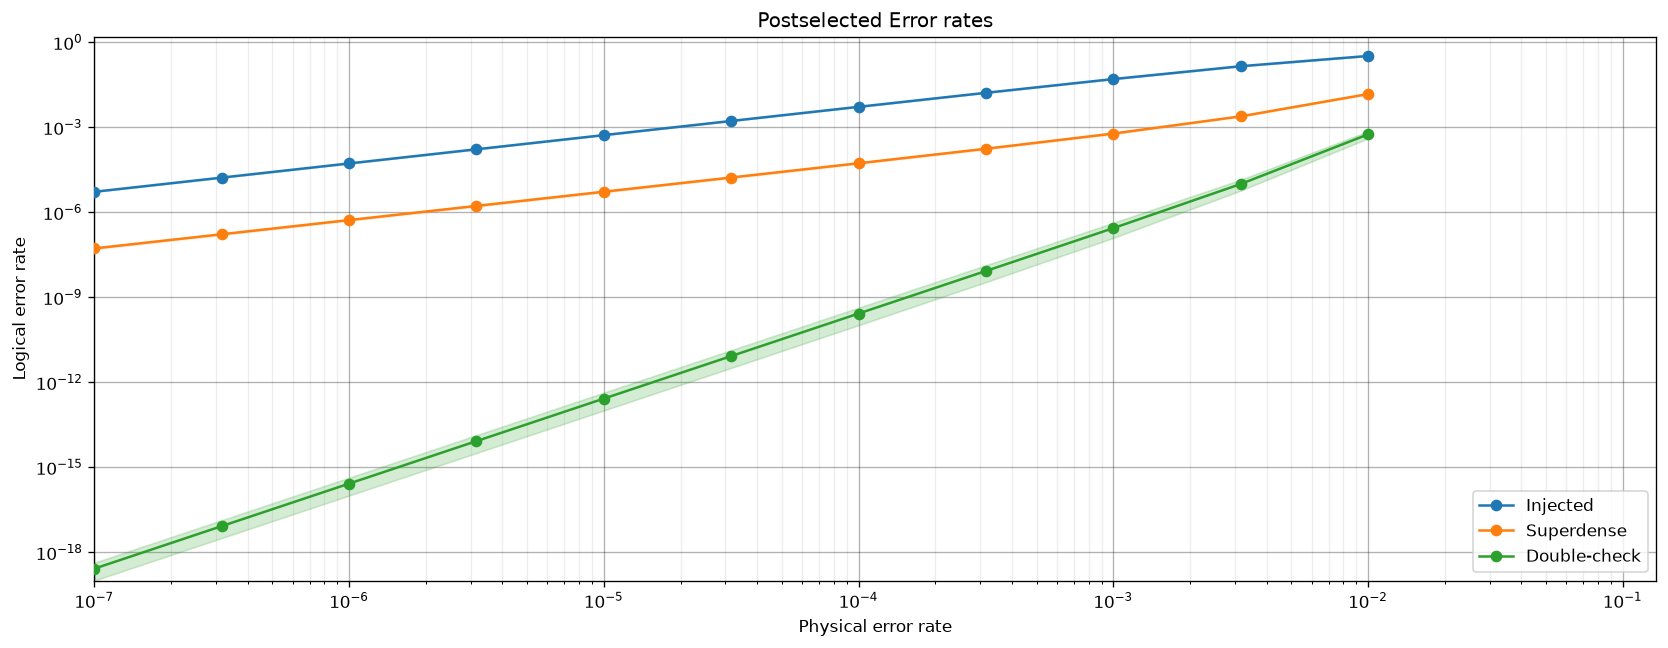

In [9]:
plot_logical_error_rates(ler_curves)

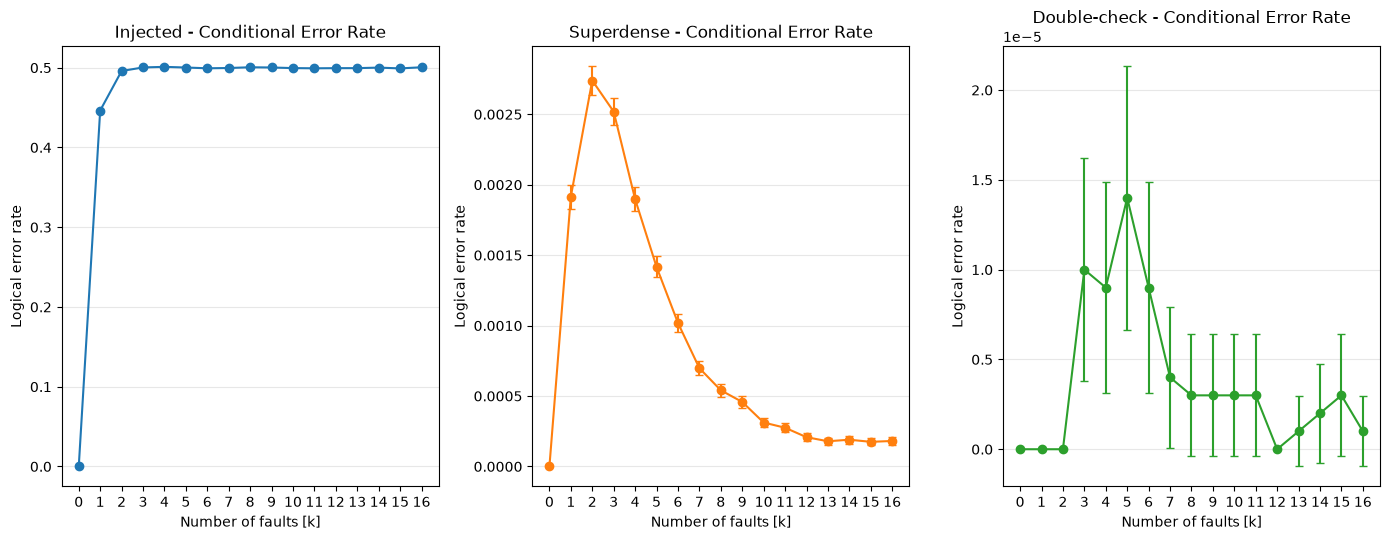

In [10]:
plot_conditional_error_rates(cer_distributions)